# Simulated data

Simulated recordings come with their ground truth, so methods can be checked
against it. This notebook shows how to build simulations from steps, what the
ground truth contains, and how to simulate new recordings from a fitted
timescale model. The concepts are explained in the
[user guide](../user_guide/simulation.rst).

<div class="alert alert-warning">

**Experimental:** the latent pupil size comes from the
[timescale model](../experimental/timescale_model.ipynb), which is
experimental; the API of the simulations may still change.

</div>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pypillometry as pp

pp.logging_set_level("WARNING")

## A first simulation

A `Simulation` is a recipe: the duration, sampling rate, eyes and seed of the
recording, and a chain of steps. Here: the latent pupil size from the timescale
model with typical parameters (the centre of the general prior), the units of
the tracker (a median pupil size of 800) and white noise of 0.5 log-%:

In [2]:
sim = (pp.sim.Simulation("5 min", fs=500, seed=1)
       .pupil()
       .units(median=800)
       .noise(0.5))
sim

Simulation(300 s at 500 Hz, eyes=['left'], seed=1)
  .TimescalePupil()
  .Units(median=800)
  .WhiteNoise(sd=0.5)

Nothing is simulated yet. `run()` makes the data, a `SimEyeData` object. It
is an `EyeData` object (all methods and plots work), with the ground truth in
`d.truth` and the recipe in `d.simulation`:

SimEyeData(fidaludi, 2.9MiB):
 n                 : 150000
 sampling_rate     : 500.0
 eyes              : ['left']
 data              : ['left_pupil']
 nevents           : 0
 experimental_setup: not set
 calibration       : not available
 duration_minutes  : 5.0
 start_min         : 0.0
 end_min           : 5.0
 params            : {}
 nblinks           : {}
 blinks            : {}
 glimpse           : EyeDataDict(vars=1,n=150000,shape=(150000,)): 
  left_pupil (float64): 832.2373, 820.7911, 834.2614, 830.7793, 826.707...

 Simulation: Simulation(300 s at 500 Hz, eyes=['left'], seed=1)
     .TimescalePupil()
     .Units(median=800)
     .WhiteNoise(sd=0.5)
 Truth: log_size, log_fast, log_3s, log_10s, log_30s, log_100s, log_300s, log_slow, size, pupil (left)
 History:
 *
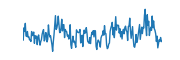

In [3]:
d = sim.run()
d

`d.plot.plot_truth()` shows the data with the true pupil (without the
noise):

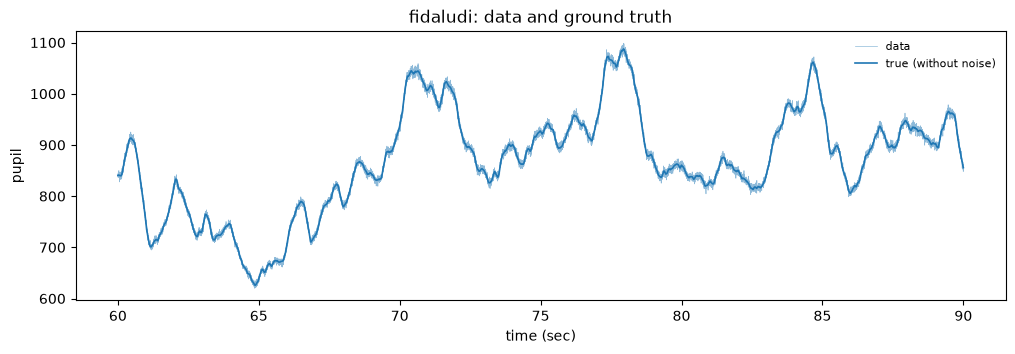

In [4]:
plt.figure(figsize=(12, 3.5))
d.plot.plot_truth(plot_range=(60, 90));

## The ground truth

`d.truth` holds the true time series, one value per sample: the pupil without
noise (`pupil`), the true size (`size`; the same here, it differs with
foreshortening), and the components of the latent signal in log-%
(`log_size` is their sum; `log_slow` collects the atoms with time scales of at
least 10 s):

In [5]:
d.truth.variables

['log_size',
 'log_fast',
 'log_3s',
 'log_10s',
 'log_30s',
 'log_100s',
 'log_300s',
 'log_slow',
 'size',
 'pupil']

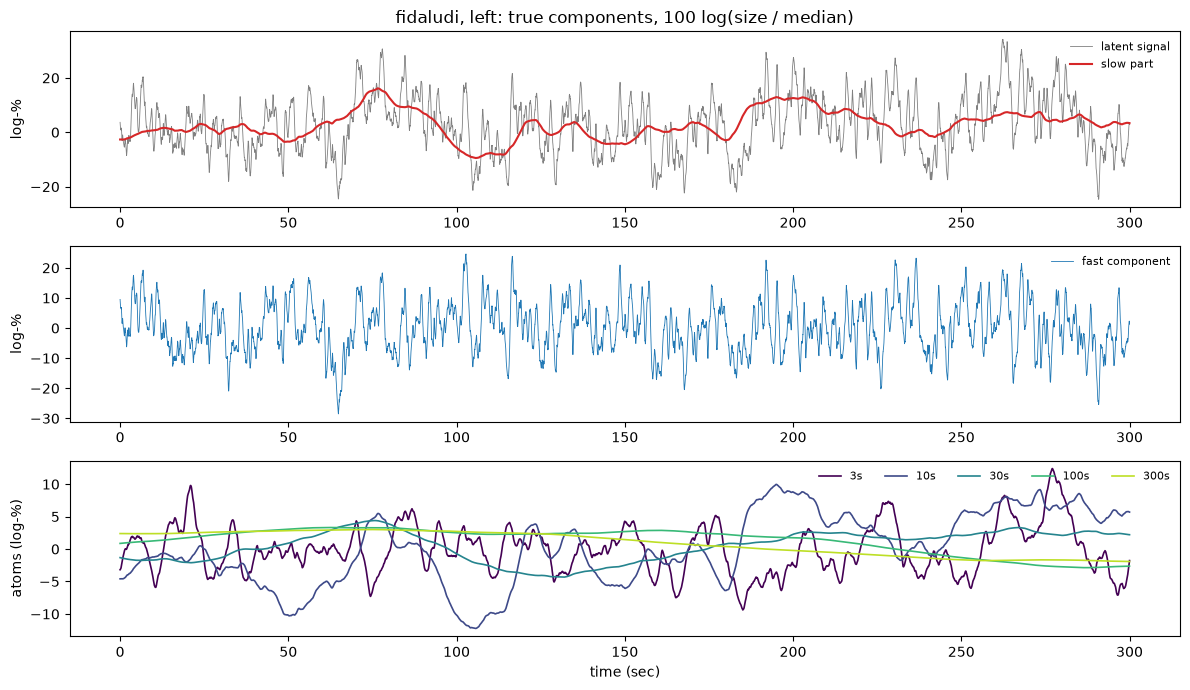

In [6]:
d.plot.plot_components(figsize=(12, 7));

The ground truth follows the samples: after cropping or downsampling, it
still matches the data.

In [7]:
dd = d.downsample(50, inplace=False).crop(60, 90, units="sec", inplace=False)
len(dd), len(dd.truth["left", "pupil"])

(1500, 1500)

## Both eyes

With two eyes, `binocular=True` gives both eyes the same fast component and
atoms (with a `gain` between them) and adds a difference between the eyes
(`diff_sd`, `diff_ell`). Parameters that are not given keep their typical
values. The median can be set per eye:

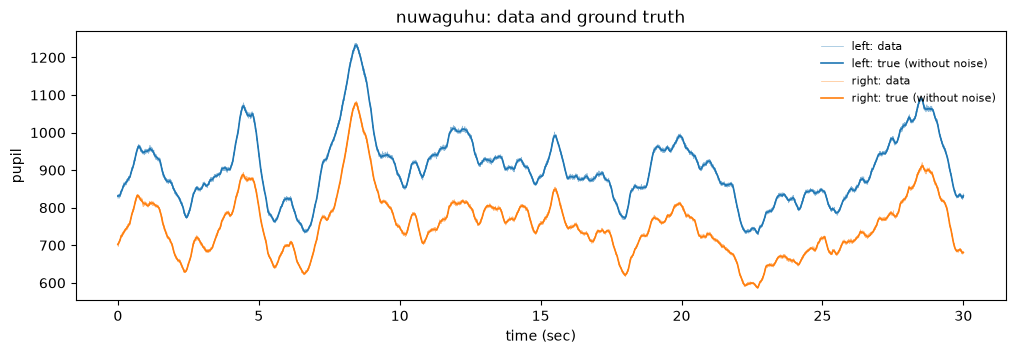

In [8]:
d2 = (pp.sim.Simulation("2 min", fs=500, eyes=["left", "right"], seed=2)
      .pupil(binocular=True, params={"diff_sd": 3.0, "gain": 1.1})
      .units(median={"left": 900, "right": 750})
      .noise(0.3)
      .run())
plt.figure(figsize=(12, 3.5))
d2.plot.plot_truth(plot_range=(0, 30));

## Varying a recipe

Each method of a simulation returns a new simulation, so one base recipe can be
varied. Each step draws from its own random stream, so the variants share
everything except what was changed: here, the same latent pupil with
different amounts of noise.

In [9]:
base = pp.sim.Simulation("5 min", fs=500, seed=3).pupil().units(800)
noisy = {sd: base.noise(sd).run() for sd in (0.2, 1.0, 3.0)}
np.array_equal(noisy[0.2].truth["left", "pupil"], noisy[3.0].truth["left", "pupil"])

True

## Checking a method against the truth

With the truth at hand, the error of a method is one line. For example, how
well does a low-pass filter recover the true pupil at each noise level, for
several cutoff frequencies?

In [10]:
def rmse(d, filtered):
    true = d.truth["left", "pupil"]
    return np.sqrt(np.mean((np.asarray(filtered["left_pupil"]) - true) ** 2))

errors = pd.DataFrame({
    f"noise {sd} log-%": {f"{cutoff} Hz": rmse(dn, dn.pupil.lowpass_filter(cutoff, inplace=False))
                          for cutoff in (1, 4, 10, 30)}
    for sd, dn in noisy.items()})
errors.round(2)

,noise 0.2 log-%,noise 1.0 log-%,noise 3.0 log-%
1 Hz,8.55,8.57,8.69
4 Hz,1.23,1.55,3.10
10 Hz,0.43,1.50,4.42
30 Hz,0.51,2.54,7.63


## Tasks and events

A `Task` describes the design of an experiment and makes the events of the
recording. It is built by chaining as well: `block()` starts a block of trials,
`stimulus()` and `response()` add events to each trial, `rest()` adds a pause
and `repeat()` repeats the blocks. Times are fixed or distributions, given as
strings. Here, the sustained attention to response task (SART): a digit every
1150 ms, masked after 250 ms; press for every digit except 3. In a notebook, a
task shows a schematic of its trials:

In [11]:
sart = (pp.sim.Task("SART")
        .block(n=225, soa="1150 ms", conditions={"go": 8/9, "nogo": 1/9})
        .stimulus("digit", "visual", duration="250 ms",
                  meta={"digit": {"go": [1, 2, 4, 5, 6, 7, 8, 9], "nogo": [3]}})
        .stimulus("mask", "visual", at="250 ms", duration="900 ms")
        .response("press", after="digit", rt="lognormal(350 ms, 70 ms)",
                  p={"go": 0.97, "nogo": 0.3}))
sart

Task('SART'): 1 block(s)
  1. 225 trials, SOA 1.15 s, go 89% / nogo 11%
     - stimulus 'digit' (visual), 250 ms, meta digit
     - stimulus 'mask' (visual), at 250 ms, 900 ms
     - response 'press' (motor) after 'digit', rt lognormal(350 ms, 70 ms), p go 0.97 / nogo 0.3

The same task (and the PVT, the FT-RSGT and the n-back task) is available
ready-made in `pp.sim.tasks`, with arguments for its parameters. The FT-RSGT
has two blocks, tapping with a beep and a thought probe, repeated for 20
minutes; `task.plot()` draws the schematic with matplotlib:

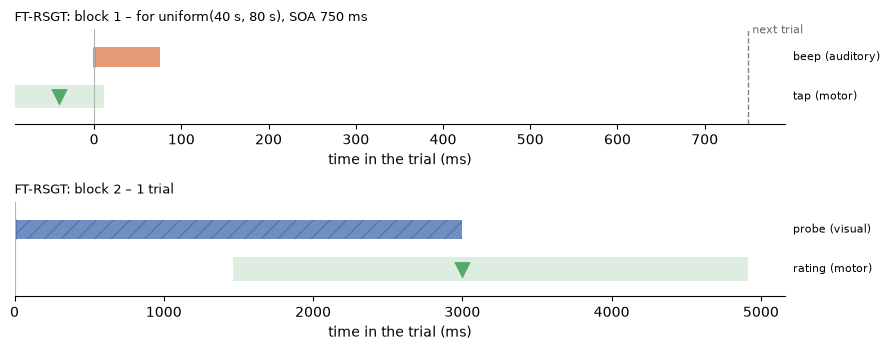

In [12]:
pp.sim.tasks.ftrsgt().plot();

Added to a simulation, the task makes the events of the data. Without a
duration, the recording lasts until the end of the task. The events carry
their metadata (trial, condition, reaction time, the digit, ...), so they can
be used like those of a real recording; for now, they do not change the
pupil.

In [13]:
ds = (pp.sim.Simulation(fs=500, seed=6)
      .task(pp.sim.tasks.sart(n=60), start="2 s")
      .pupil().units(800).noise(0.5)
      .run())
ds.events

,Onset (ms),Label,kind,modality,trial,block,condition,duration,luminance,rt,digit
0,2000.000000,digit,stimulus,visual,0,1,go,250.0,NaN,NaN,6.0
1,2250.000000,mask,stimulus,visual,0,1,go,900.0,NaN,NaN,NaN
2,2346.488905,press,response,motor,0,1,go,NaN,NaN,346.488905,NaN
3,3150.000000,digit,stimulus,visual,1,1,go,250.0,NaN,NaN,2.0
4,3400.000000,mask,stimulus,visual,1,1,go,900.0,NaN,NaN,NaN
5,3472.199112,press,response,motor,1,1,go,NaN,NaN,322.199112,NaN
6,4300.000000,digit,stimulus,visual,2,1,go,250.0,NaN,NaN,6.0
7,4550.000000,mask,stimulus,visual,2,1,go,900.0,NaN,NaN,NaN
8,4645.804215,press,response,motor,2,1,go,NaN,NaN,345.804215,NaN
9,5450.000000,digit,stimulus,visual,3,1,go,250.0,NaN,NaN,7.0


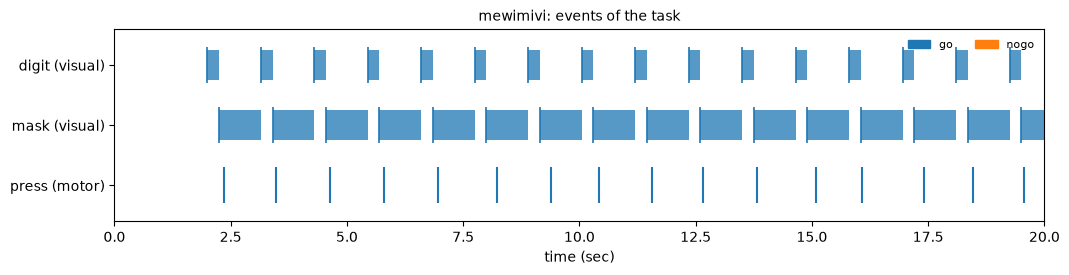

In [14]:
plt.figure(figsize=(12, 2.5))
ds.plot.plot_task_events(plot_range=(0, 20));

For example, the commission errors (presses in no-go trials) and the mean
reaction time in go trials:

In [15]:
ev = ds.events
press = ev.labels == "press"
nogo_trials = ev.meta["trial"][(ev.labels == "digit") & (ev.meta["condition"] == "nogo")]
print("no-go trials:", len(nogo_trials),
      "| commission errors:", np.isin(ev.meta["trial"][press], nogo_trials).sum(),
      "| mean RT (go):", round(np.mean(ev.meta["rt"][press & (ev.meta["condition"] == "go")])), "ms")

no-go trials: 9 | commission errors: 3 | mean RT (go): 348 ms


## From a fitted model

A fitted `TimescaleModel` simulates new recordings with its estimated
parameters, median pupil size and noise (`m.simulate()`). Here, the model of
the left eye of an example recording:

SimEyeData(rlmw_002_sim, 466.9KiB):
 n                 : 23893
 sampling_rate     : 20.0
 eyes              : ['left']
 data              : ['left_pupil']
 nevents           : 0
 experimental_setup: not set
 calibration       : not available
 duration_minutes  : 19.9108
 start_min         : 0.0
 end_min           : 19.91
 params            : {}
 nblinks           : {}
 blinks            : {}
 glimpse           : EyeDataDict(vars=1,n=23893,shape=(23893,)): 
  left_pupil (float64): 1050.1702, 1036.3396, 1038.4706, 1032.3253, 1034.3231...

 Simulation: Simulation(1194.65 s at 20 Hz, eyes=['left'], seed=1)
     .TimescalePupil(params={'fast_sd': 4.84, 'fast_ell': 312.8, 'sd_3s': 6.222, 'sd_10s': 1.238, 'sd_30s': 1.148, 'sd_100s': 2.088, 'sd_300s': 1.091}, timescales=(3000, 10000, 30000, 100000, 300000), eyes=('left',))
     .Units(median={'left': 1055})
     .WhiteNoise(sd=0.314, eyes=('left',))
 Truth: log_size, log_fast, log_3s, log_10s, log_30s, log_100s, log_300s, log_slow, size, pupil (left)
 History:
 *
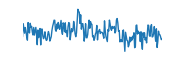

In [16]:
data = pp.get_example_data("rlmw_002").pupil.blinks_detect()
m = pp.TimescaleModel(data, eyes="left").fit(progress=False)
s = m.simulate(seed=1)
s

The simulation has the sampling rate of the model (20 Hz) and, by default,
the duration of its data. Comparing the decomposition of the recording with
the true components of a simulation shows whether the model produces
recordings that look like the real one:

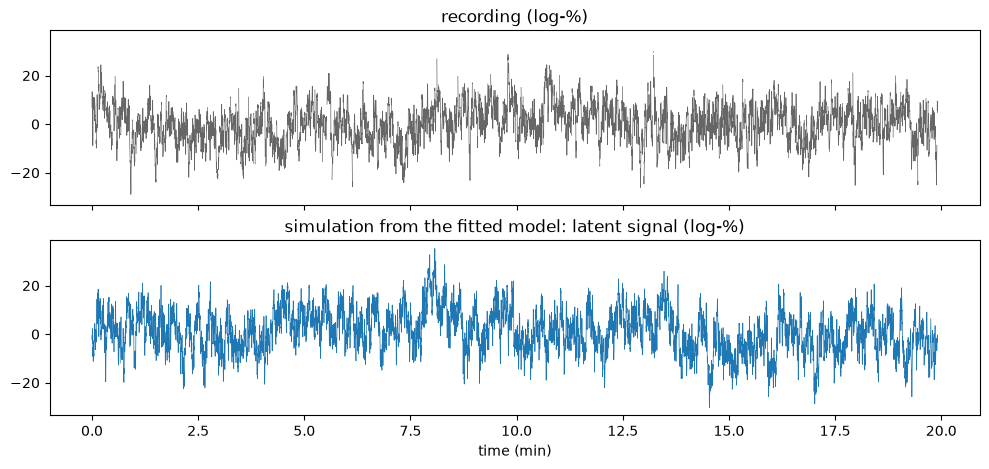

In [17]:
fig, axs = plt.subplots(2, 1, figsize=(12, 5), sharex=True, sharey=True)
axs[0].plot(m.time / 60000, m.y["left"], lw=0.5, color="0.4")
axs[0].set_title("recording (log-%)")
axs[1].plot(s.tx / 60000, s.truth["left", "log_size"], lw=0.5, color="C0")
axs[1].set_title("simulation from the fitted model: latent signal (log-%)")
axs[1].set_xlabel("time (min)");

Fitting the model again to simulated data shows how well its parameters can
be recovered from a recording of this length. The fast component and the noise
come back closely; the variances of the single atoms much less so, which is
why the model uses a prior for them:

In [18]:
m2 = pp.TimescaleModel(s).fit(progress=False)
pd.DataFrame({"true (fitted to the recording)": m.params["left"],
              "estimated from the simulation": m2.params["left"]}).round(2)

,true (fitted to the recording),estimated from the simulation
fast_sd,4.84,4.85
fast_ell,312.79,314.46
noise_sd,0.31,0.32
sd_3s,6.22,5.71
sd_10s,1.24,2.74
sd_30s,1.15,1.69
sd_100s,2.09,2.85
sd_300s,1.09,1.60


`m.process()` returns the latent pupil of the model as steps, to build other
simulations with it, e.g. at the sampling rate of the tracker with another
noise:

In [19]:
s1k = (pp.sim.Simulation("1 min", fs=1000, seed=4)
       .pupil(*m.process())
       .units(m.scale["left"])
       .noise(1.0)
       .run())
s1k.simulation

Simulation(60 s at 1000 Hz, eyes=['left'], seed=4)
  .TimescalePupil(params={'fast_sd': 4.84, 'fast_ell': 312.8, 'sd_3s': 6.222, 'sd_10s': 1.238, 'sd_30s': 1.148, 'sd_100s': 2.088, 'sd_300s': 1.091}, timescales=(3000, 10000, 30000, 100000, 300000), eyes=('left',))
  .Units(median=1055)
  .WhiteNoise(sd=1)

## Gaze and foreshortening

With an experimental setup, the simulation can add gaze (fixations at random
places on the screen) and the foreshortening of the pupil, which depends on
where the eye looks. The true size and the foreshortening factor are part of
the truth. The [foreshortening notebook](../experimental/foreshortening.ipynb)
uses such data to fit the camera position.

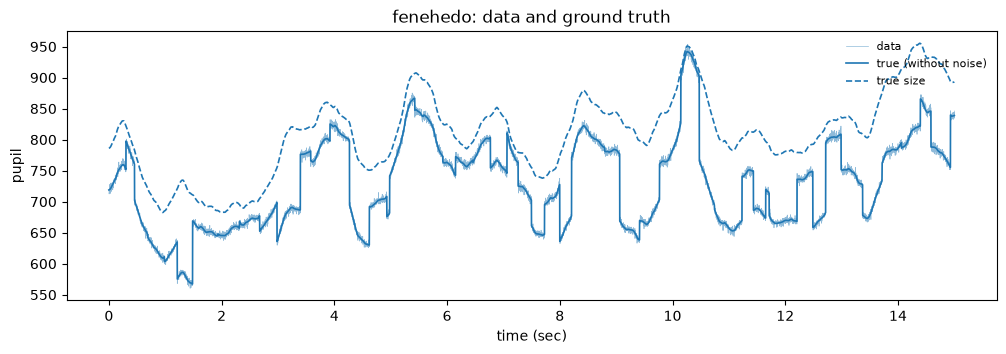

In [20]:
setup = pp.ExperimentalSetup(screen_resolution=(1920, 1080),
                             physical_screen_size=("52 cm", "29 cm"),
                             eye_to_screen_center="60 cm",
                             camera_spherical=("20 deg", "-90 deg", "70 cm"))
fd = (pp.sim.Simulation("1 min", fs=500, seed=5, setup=setup)
      .pupil().gaze().foreshortening().units(750).noise(0.5)
      .run())
plt.figure(figsize=(12, 3.5))
fd.plot.plot_truth(plot_range=(0, 15));

## Reproducibility and saving

`d.simulation` holds the recipe together with the seed, so the same data can
be made again, or new data from the same recipe. Saved simulated data keep
their ground truth and recipe.

In [21]:
same = d.simulation.run()
new = d.simulation.run(seed=99)
np.array_equal(same["left_pupil"], d["left_pupil"]), np.array_equal(new["left_pupil"], d["left_pupil"])

(True, False)